<a href="https://colab.research.google.com/github/bhanukaT56/setExercises/blob/asel-exercise01/Exrecise_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 1: Multi-Layer Perceptron (MLP) Classifier
**Module:** PUSL3123 AI and Machine Learning | **Dataset:** CIFAR-10 | **Framework:** PyTorch



## 1. Setup and Data Loading

In [ ]:
import torch, torch.nn as nn
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np, random


SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
base_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=base_tf)
test_set   = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=base_tf)
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader   = DataLoader(Subset(full_train, val_idx),   batch_size=128, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=128, num_workers=2)


def run_epoch(model, loader, criterion, optimizer=None):

    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, epochs=20, lr=1e-3):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        print(f"Epoch {ep+1:2d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")
    return h

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def plot_history(h, title):
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h["train_loss"], label="train"); ax[0].plot(epochs, h["val_loss"], label="validation")
    ax[0].set(title=f"{title}: loss", xlabel="epoch", ylabel="loss"); ax[0].legend()
    ax[1].plot(epochs, h["train_acc"], label="train"); ax[1].plot(epochs, h["val_acc"], label="validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="epoch", ylabel="accuracy"); ax[1].legend()
    plt.show()


print("Train / val / test sizes:", len(train_idx), len(val_idx), len(test_set))

Device: cuda


100%|██████████| 170M/170M [31:11<00:00, 91.1kB/s]


Train / val / test sizes: 45000 5000 10000


## 2. Data Inspection

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Batch shape: torch.Size([128, 3, 32, 32]) | Labels shape: torch.Size([128])


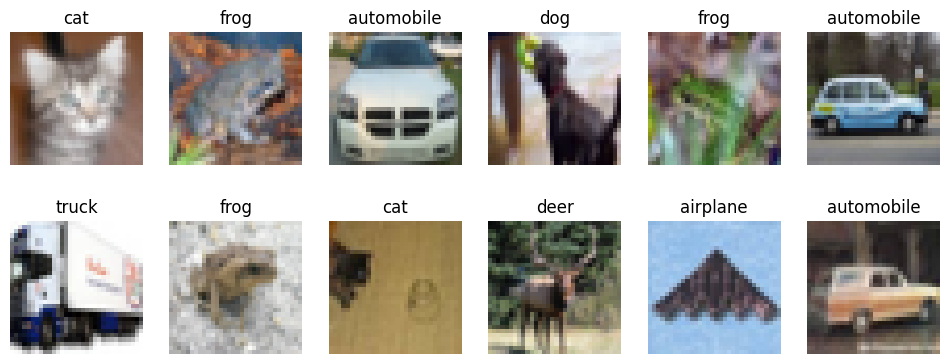

In [ ]:
class_names = full_train.classes
print("Classes:", class_names)

x, y = next(iter(train_loader))
print("Batch shape:", x.shape, "| Labels shape:", y.shape)   # [128, 3, 32, 32]

mean = torch.tensor(MEAN).view(3, 1, 1); std = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, lbl in zip(axes.flat, x[:12], y[:12]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(class_names[lbl]); ax.axis("off")
plt.show()

## 3. MLP Model Definition

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, h1=512, h2=256, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, h1), nn.ReLU(),   # trainable layer 1
            nn.Linear(h1, h2),     nn.ReLU(),   # trainable layer 2
            nn.Linear(h2, n_classes)            # trainable layer 3 (logits)
        )
    def forward(self, x):
        return self.net(x)

## 4. Model Training

In [ ]:
torch.manual_seed(SEED)
mlp = MLP()
print(mlp)
print("Trainable parameters:", f"{count_params(mlp):,}")   # 1,707,274

history = fit(mlp, train_loader, val_loader, epochs=20, lr=1e-3)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 1,707,274
Epoch  1 | train loss 1.653 acc 0.413 | val loss 1.539 acc 0.466
Epoch  2 | train loss 1.446 acc 0.486 | val loss 1.456 acc 0.479
Epoch  3 | train loss 1.330 acc 0.531 | val loss 1.423 acc 0.498
Epoch  4 | train loss 1.246 acc 0.561 | val loss 1.415 acc 0.509
Epoch  5 | train loss 1.159 acc 0.589 | val loss 1.384 acc 0.525
Epoch  6 | train loss 1.088 acc 0.615 | val loss 1.396 acc 0.522
Epoch  7 | train loss 1.013 acc 0.642 | val loss 1.416 acc 0.524
Epoch  8 | train loss 0.936 acc 0.667 | val loss 1.476 acc 0.520
Epoch  9 | train loss 0.869 acc 0.693 | val loss 1.504 acc 0.512
Epoch 10 | train loss 0.807 acc 0.712 | val loss 1.586 acc 0.525
Epoch 11 | train loss 0.73

## 5. Training and Validation Curves

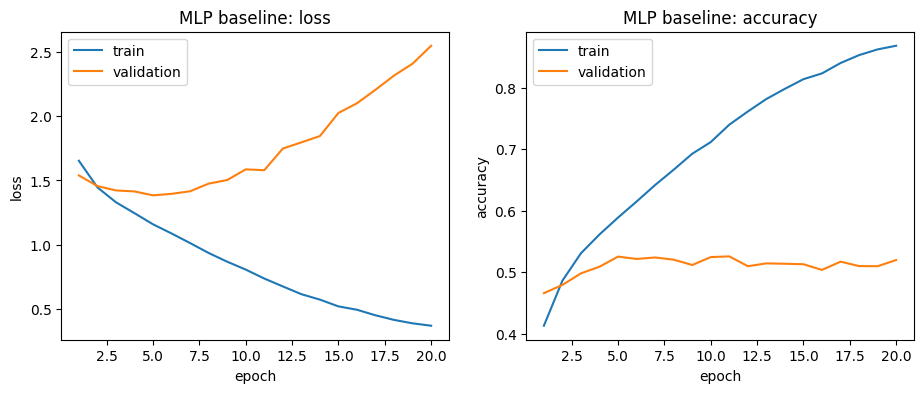

In [ ]:
plot_history(history, "MLP baseline")

## 6. Final Evaluation and Saving Results

In [ ]:
import json

# Guard: the model must have been trained in this session
if 'mlp' not in globals() or 'history' not in globals():
    raise RuntimeError("Run Cell 3 (train the model) first, then re-run this cell.")

# ---- Final evaluation (test set used once, after training) ----
criterion = nn.CrossEntropyLoss()
tr_loss, tr_acc = run_epoch(mlp, train_loader, criterion)
va_loss, va_acc = run_epoch(mlp, val_loader,   criterion)
te_loss, te_acc = run_epoch(mlp, test_loader,  criterion)

print(f"{'Split':<12}{'Loss':>8}{'Accuracy':>10}")
for name, l, a in [("Train", tr_loss, tr_acc),
                   ("Validation", va_loss, va_acc),
                   ("Test", te_loss, te_acc)]:
    print(f"{name:<12}{l:>8.3f}{a:>10.3%}")
print(f"\nTrain-test accuracy gap: {tr_acc - te_acc:.3%}")

# ---- Save results for Exercise 2 ----
results = {
    "model": "MLP",
    "params": count_params(mlp),
    "train_acc": tr_acc, "val_acc": va_acc, "test_acc": te_acc,
    "train_loss": tr_loss, "val_loss": va_loss, "test_loss": te_loss,
    "history": history,
}
with open("exercise1_mlp_results.json", "w") as f:
    json.dump(results, f)
torch.save(mlp.state_dict(), "exercise1_mlp.pt")
print("Saved.")

Split           Loss  Accuracy
Train          0.309   89.104%
Validation     2.547   51.980%
Test           2.531   52.830%

Train-test accuracy gap: 36.274%
Saved.


## 7. Confusion Matrix and Classification Report

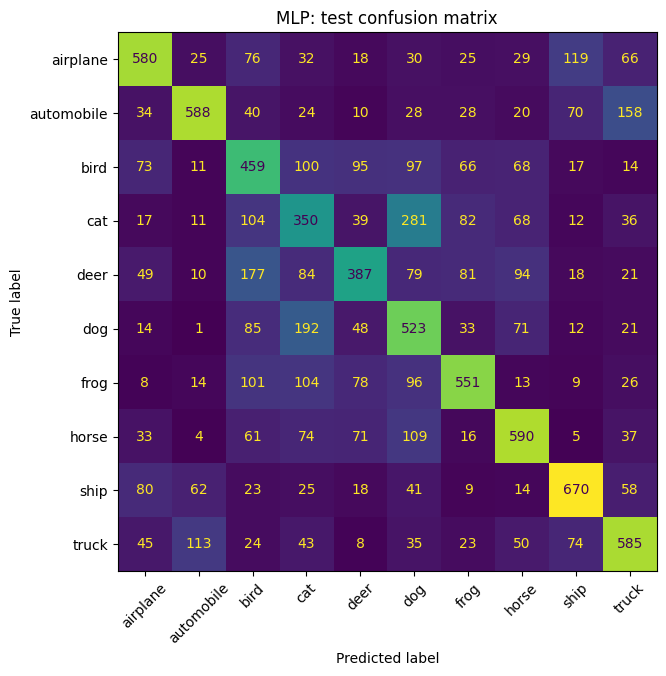

              precision    recall  f1-score   support

    airplane      0.622     0.580     0.600      1000
  automobile      0.701     0.588     0.639      1000
        bird      0.399     0.459     0.427      1000
         cat      0.340     0.350     0.345      1000
        deer      0.501     0.387     0.437      1000
         dog      0.397     0.523     0.451      1000
        frog      0.603     0.551     0.576      1000
       horse      0.580     0.590     0.585      1000
        ship      0.666     0.670     0.668      1000
       truck      0.572     0.585     0.579      1000

    accuracy                          0.528     10000
   macro avg      0.538     0.528     0.531     10000
weighted avg      0.538     0.528     0.531     10000



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

@torch.no_grad()
def get_predictions(model, loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(1).cpu())
        labels.append(y)
    return torch.cat(labels).numpy(), torch.cat(preds).numpy()

y_true, y_pred = get_predictions(mlp, test_loader)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("MLP: test confusion matrix")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))